In [13]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import numpy as np
import config as c

## let's check if memmap works (loading by indices)

In [2]:
fpr = np.memmap(c.signals_path, 
                dtype = c.dtype, 
                mode = 'r', #only reading
                shape = (c.N_exams, c.N_windows, c.N_channels, c.Window_len*c.Fs))

### shape & choice check

In [3]:
fpr[150].shape

(150, 17, 768)

In [4]:
single_exam = fpr[12]

### units check (expected Volts, so 1e-6 or 1e-5 in notation)

In [5]:
single_exam

memmap([[[-1.38042842e-05, -1.19573167e-04, -7.98815090e-05, ...,
          -1.68772895e-05, -1.23170230e-05, -6.29669648e-06],
         [ 2.71838890e-05,  2.13709078e-04,  1.51491156e-04, ...,
          -2.31929316e-05, -1.33903513e-05, -6.46522540e-06],
         [ 1.00673824e-05,  2.15099280e-05,  2.14221218e-05, ...,
           6.87500460e-07,  8.50752986e-06,  1.63042077e-05],
         ...,
         [-1.29074888e-05, -5.20026151e-05, -4.25048820e-05, ...,
          -2.78100651e-05, -2.80016666e-05, -2.43990289e-05],
         [-6.19948378e-06, -8.78096107e-05, -5.48749267e-05, ...,
          -7.20849300e-07,  1.63870561e-06,  3.07941104e-06],
         [-1.00652760e-05, -2.29079124e-05, -2.51606562e-05, ...,
          -1.63172044e-05, -1.87733986e-05, -2.08523452e-05]],

        [[-2.22822428e-06,  2.03430977e-06,  1.06938269e-05, ...,
          -1.14154282e-05, -8.28963857e-06, -2.17005413e-06],
         [-5.43617853e-06, -6.95790914e-06, -5.84764393e-06, ...,
          -1.41037526e

### check how it looks on plot (use MNE for readability and epoch alignement)

Not setting metadata
150 matching events found
No baseline correction applied
0 projection items activated
Using matplotlib as 2D backend.


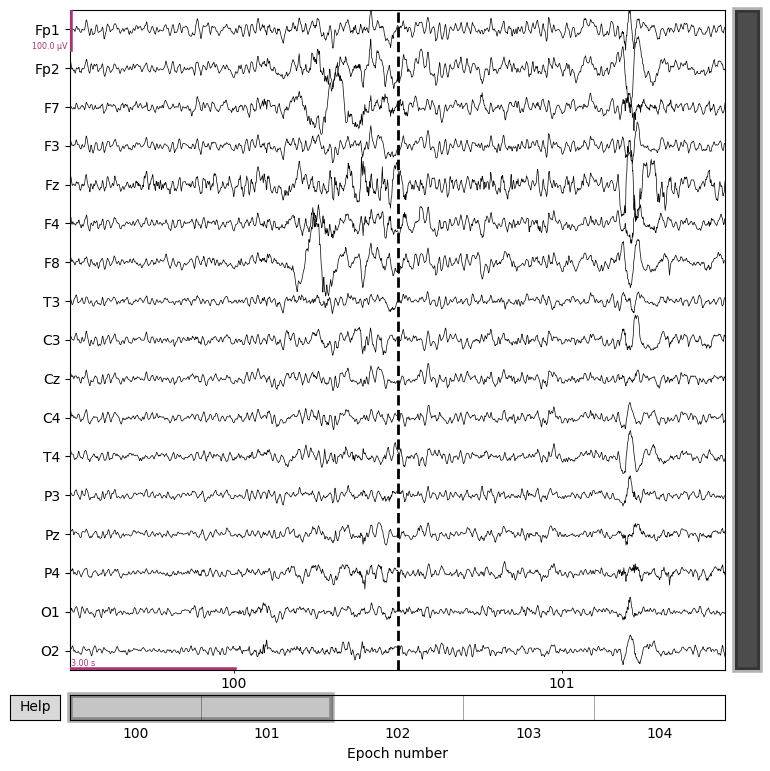

In [6]:
import mne


info = mne.create_info(['Fp1','Fp2','F7','F3','Fz','F4','F8','T3','C3','Cz','C4','T4','P3','Pz','P4','O1','O2'], sfreq=128, ch_types="eeg")  
epochs = mne.EpochsArray(single_exam, info, tmin=0, baseline=None)
g = epochs[100:105].plot(n_epochs=2, scalings=dict(eeg=50e-6))


### check psd

Set montage to plot psd with channels labeling and sensors annotations on topological head.

In [7]:
epochs.set_montage("colin27_1020")

<EpochsArray | 150 events (all good), 0 – 5.992 s (baseline off), ~15.0 MiB, data loaded,
 '1': 150>

NOTE: plot_psd() is a legacy function. New code should use .compute_psd().plot().
    Using multitaper spectrum estimation with 7 DPSS windows
Plotting power spectral density (dB=True).
Averaging across epochs before plotting...


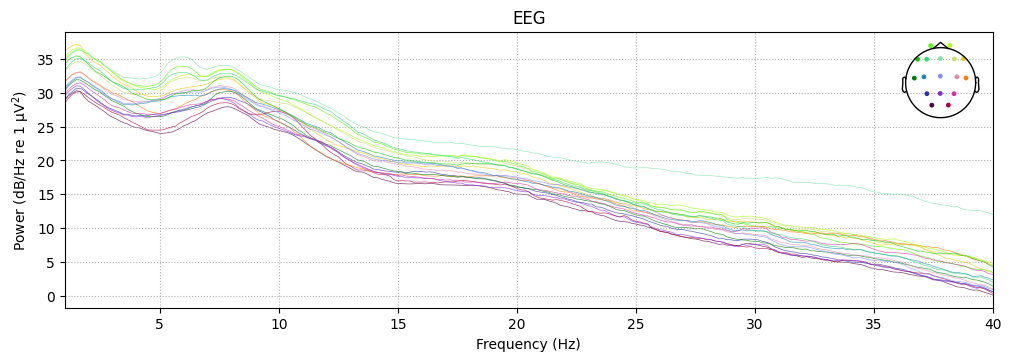

In [8]:
g = epochs.plot_psd(fmin = 1, fmax = 40, picks = "eeg", spatial_colors=True)

## explore dataset splitting methods

Comment from scikit-learn:
- Choosing the right cross-validation object is a crucial part of fitting a model properly. 
- There are **many** ways to split data into training and test sets in order to avoid model overfitting, to standardize the number of groups in test sets, etc.

In the multi-site dataset it is very important to avoid leakage and split by site groups with demographics and label stratification.

### load metadata (aligned with eeg database per indices)

In [9]:
meta = pd.read_csv(c.metadata_path)
meta

,site,patient_id,exam_id,age,age_group,female,pathology
0,S00,P28505,20220512-162946-{3ad3c86b-3d61-440e-81df-b74fd...,36.9,36-45,0,1
1,S00,P28499,20220512-163059-{c7e51449-0539-4208-9962-61bd1...,50.5,46-55,1,1
2,S00,P28497,20220512-162502-{e7d9d501-f72e-4045-afaf-d8827...,45.2,36-45,1,1
3,S00,P28496,20220512-170457-{f141a0b0-1275-435f-9cf1-4ead3...,23.4,16-25,1,0
4,S00,P28496,20220512-163126-{4b9b23b2-ef37-4efb-9d38-c1909...,17.8,16-25,1,1
...,...,...,...,...,...,...,...
38537,S29,P32549,20220602-152610-{7008a1d7-3ce6-4a20-9b1c-3df5a...,16.2,16-25,0,0
38538,S29,P32548,20220602-152655-{f7a40810-55c6-4f15-a461-76758...,62.7,56-65,0,1
38539,S29,P32547,20220602-152850-{7f63b022-3c53-4b2c-80ff-69e79...,40.2,36-45,0,0
38540,S29,P29278,20220602-152230-{f52ece77-e74b-493c-9524-beec6...,17.5,16-25,0,0


In [10]:
y = meta['pathology']
y

0        1
1        1
2        1
3        0
4        1
        ..
38537    0
38538    1
38539    0
38540    0
38541    1
Name: pathology, Length: 38542, dtype: int64

In [11]:
groups = meta['site']

In [21]:
unique_groups = list(groups)
group_mapping = {g: i for i, g in enumerate(unique_groups)}
group_indices = [group_mapping[g] for g in groups]

### create color pallette to capture all sites on the split bar

In [14]:
# Source - https://stackoverflow.com/a/59998512
# Posted by Greg0ry, modified by community. See post 'Timeline' for change history
# Retrieved 2026-10-10, License - CC BY-SA 4.0

import math
from matplotlib.colors import ListedColormap
from matplotlib.cm import hsv #type:ignore


def generate_colormap(number_of_distinct_colors: int = 30):
    if number_of_distinct_colors == 0:
        number_of_distinct_colors = 80

    number_of_shades = 7
    number_of_distinct_colors_with_multiply_of_shades = int(math.ceil(number_of_distinct_colors / number_of_shades) * number_of_shades)
    linearly_distributed_nums = np.arange(number_of_distinct_colors_with_multiply_of_shades) / number_of_distinct_colors_with_multiply_of_shades
    arr_by_shade_rows = linearly_distributed_nums.reshape(number_of_shades, number_of_distinct_colors_with_multiply_of_shades // number_of_shades)
    arr_by_shade_columns = arr_by_shade_rows.T
    number_of_partitions = arr_by_shade_columns.shape[0]
    nums_distributed_like_rising_saw = arr_by_shade_columns.reshape(-1)

    # HSV colour map is cyclic (https://matplotlib.org/tutorials/colors/colormaps.html#cyclic)
    initial_cm = hsv(nums_distributed_like_rising_saw)

    lower_partitions_half = number_of_partitions // 2
    upper_partitions_half = number_of_partitions - lower_partitions_half
    lower_half = lower_partitions_half * number_of_shades
    for i in range(3):
        initial_cm[0:lower_half, i] *= np.arange(0.2, 1, 0.8/lower_half)
    for i in range(3):
        for j in range(upper_partitions_half):
            modifier = np.ones(number_of_shades) - initial_cm[lower_half + j * number_of_shades: lower_half + (j + 1) * number_of_shades, i]
            modifier = j * modifier / upper_partitions_half
            initial_cm[lower_half + j * number_of_shades: lower_half + (j + 1) * number_of_shades, i] += modifier

    return ListedColormap(initial_cm)

In [69]:
cmap_data = generate_colormap()
cmap_cv = plt.cm.coolwarm #type:ignore
n_splits = 5

def visualize_groups(classes, groups):

    fig, ax = plt.subplots(figsize = (15, 8))
    ax.scatter(
        range(len(groups)),
        [0.5] * len(groups),
        c=groups,
        marker="_",
        lw=50,
        cmap=cmap_data,
    )
    ax.scatter(
        range(len(groups)),
        [3.5] * len(groups),
        c=classes,
        marker="_",
        lw=50,
        cmap=cmap_cv,
    )
    ax.set(
        ylim=[-1, 5],
        yticks=[0.5, 3.5],
        yticklabels=["Sites", "Labels"],
        xlabel="Exam index",
    )
    return fig

f = visualize_groups(y, group_indices)

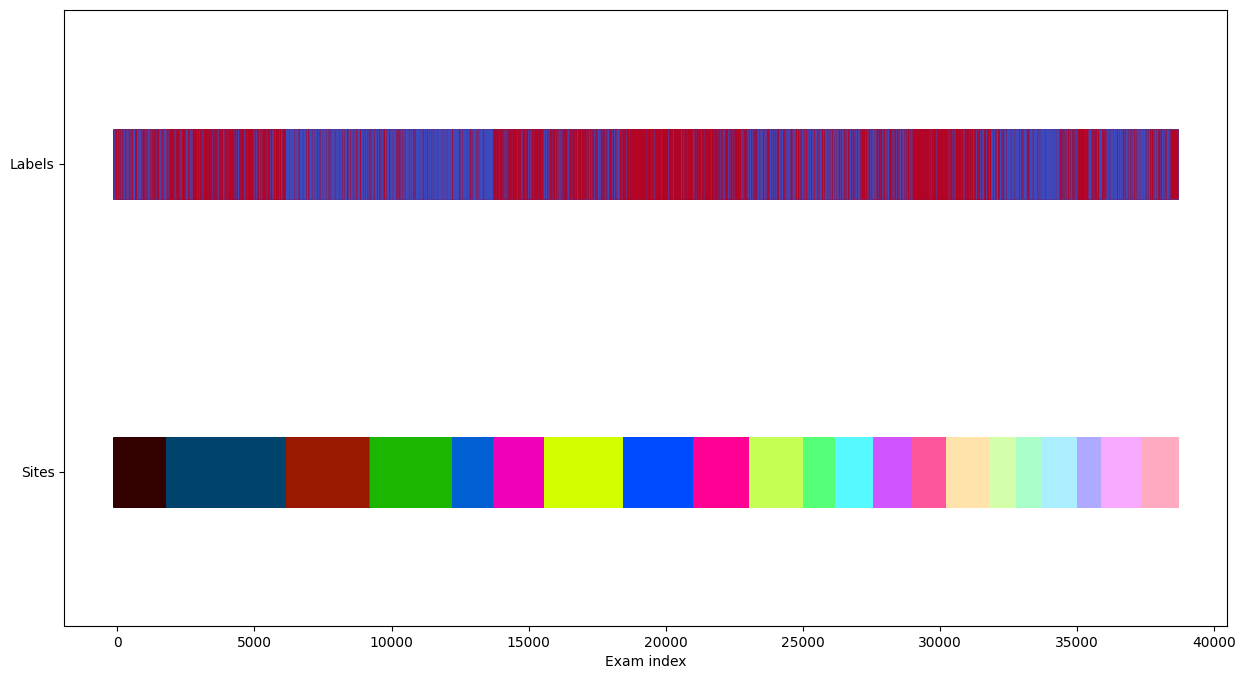

In [70]:
f

In [83]:
def plot_cv_indices(cv, X, y, group_indices, ax, n_splits, lw=10):
    """Create a sample plot for indices of a cross-validation object."""
    for ii, (tr, tt) in enumerate(cv.split(X=X, y=y, groups=group_indices)):

        indices = np.array([np.nan] * len(X))
        indices[tt] = 1
        indices[tr] = 0

        ax.scatter(
            range(len(indices)),
            [ii + 0.5] * len(indices),
            c=indices,
            marker="_",
            lw=lw,
            cmap=cmap_cv,
            vmin=-0.2,
            vmax=1.2,
        )

    ax.scatter(range(len(X)), [ii + 1.5] * len(X), c=y, marker="_", lw=lw, cmap=cmap_cv) #type:ignore
    ax.scatter(range(len(X)), [ii + 2.5] * len(X), c=group_indices, marker="_", lw=lw, cmap=cmap_data) #type:ignore
    yticklabels = list(range(n_splits)) + ["Labels", "Sites"]
    ax.set(
        yticks=np.arange(n_splits + 2) + 0.5,
        yticklabels=yticklabels,
        xlabel="Sample index",
        ylabel="CV iteration",
        ylim=[n_splits + 2.2, -0.2],
        xlim=[0, len(X)])
    ax.set_title("{}".format(type(cv).__name__), fontsize=15)
    return ax

In [84]:
from sklearn.model_selection import (GroupKFold,
                                     GroupShuffleSplit,
                                     KFold,
                                     ShuffleSplit,
                                     StratifiedGroupKFold,
                                     StratifiedKFold,
                                     StratifiedShuffleSplit,
                                     TimeSeriesSplit)

/dmj/fizmed/mmarzec/licencjat_neuro/venv_magisterka/lib/python3.11/site-packages/sklearn/model_selection/_split.py:86: UserWarning: The groups parameter is ignored by KFold
  warnings.warn(


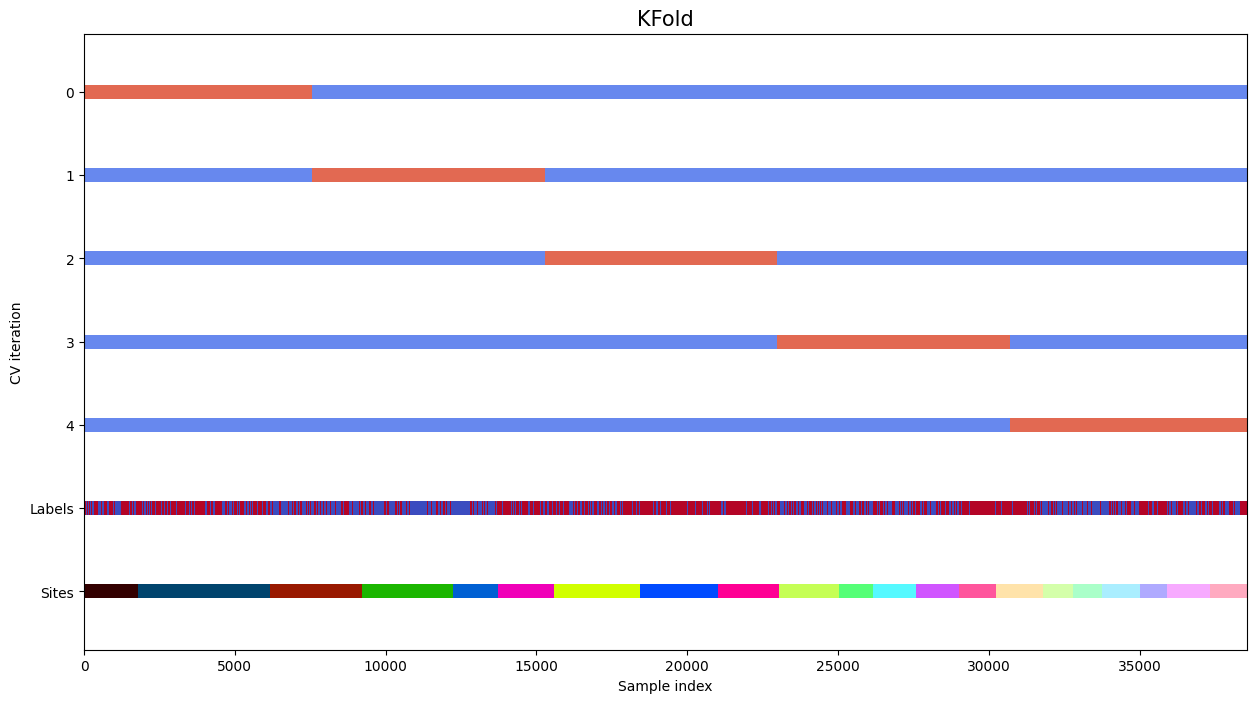

In [85]:
_, ax = plt.subplots(figsize = (15,8))
cv = KFold(n_splits)
g = plot_cv_indices(cv, fpr, y, group_indices, ax = ax, n_splits = n_splits)
plt.show()

/dmj/fizmed/mmarzec/licencjat_neuro/venv_magisterka/lib/python3.11/site-packages/sklearn/model_selection/_split.py:883: UserWarning: The groups parameter is ignored by StratifiedKFold
  warnings.warn(


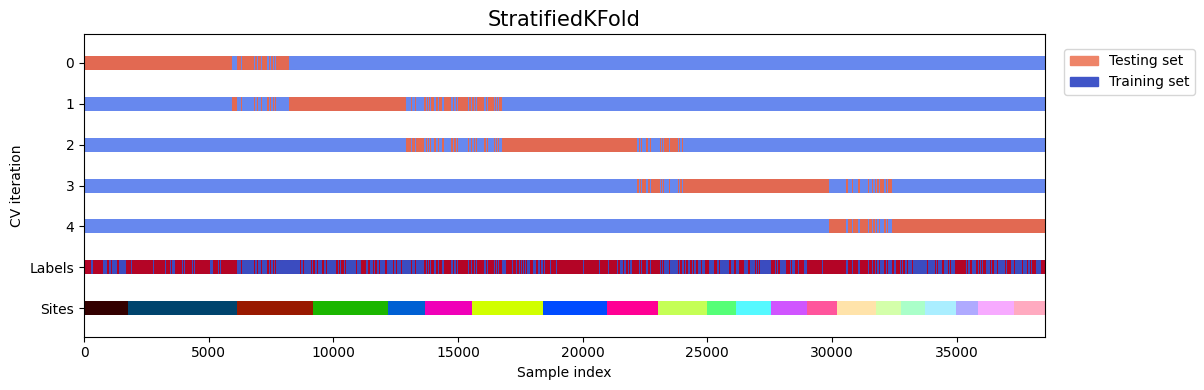

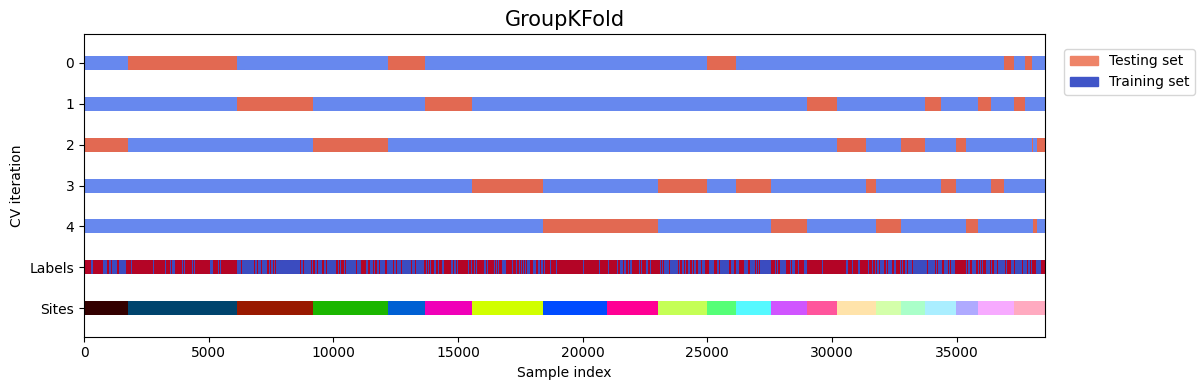

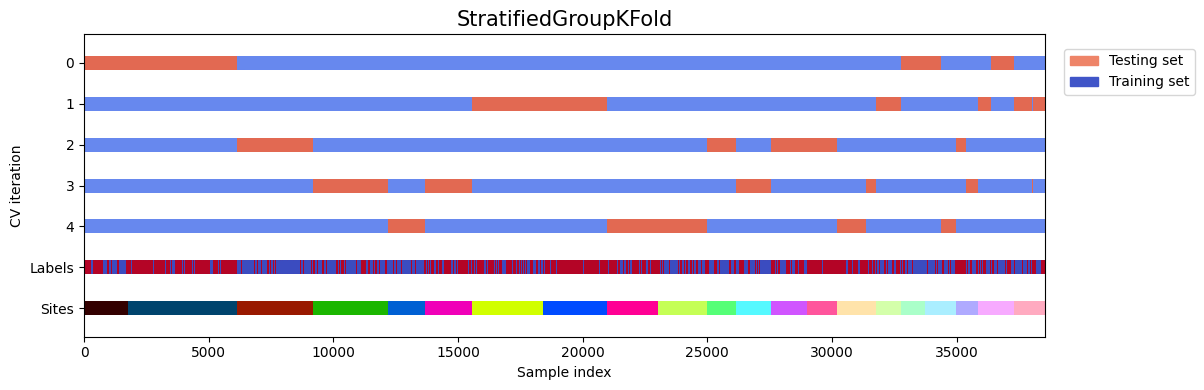

In [86]:
cvs = [StratifiedKFold, GroupKFold, StratifiedGroupKFold]

for cv in cvs:
    fig, ax = plt.subplots(figsize=(15, 4))
    plot_cv_indices(cv(n_splits), fpr, y, group_indices, ax, n_splits)
    ax.legend(
        [Patch(color=cmap_cv(0.8)), Patch(color=cmap_cv(0.02))],
        ["Testing set", "Training set"],
        loc=(1.02, 0.8),
    )
    # Make the legend fit
    plt.tight_layout()
    g = fig.subplots_adjust(right=0.7)
plt.show()

/dmj/fizmed/mmarzec/licencjat_neuro/venv_magisterka/lib/python3.11/site-packages/sklearn/model_selection/_split.py:86: UserWarning: The groups parameter is ignored by KFold
  warnings.warn(
/dmj/fizmed/mmarzec/licencjat_neuro/venv_magisterka/lib/python3.11/site-packages/sklearn/model_selection/_split.py:86: UserWarning: The groups parameter is ignored by ShuffleSplit
  warnings.warn(
/dmj/fizmed/mmarzec/licencjat_neuro/venv_magisterka/lib/python3.11/site-packages/sklearn/model_selection/_split.py:883: UserWarning: The groups parameter is ignored by StratifiedKFold
  warnings.warn(
/dmj/fizmed/mmarzec/licencjat_neuro/venv_magisterka/lib/python3.11/site-packages/sklearn/model_selection/_split.py:2425: UserWarning: The groups parameter is ignored by StratifiedShuffleSplit
  warnings.warn(
/dmj/fizmed/mmarzec/licencjat_neuro/venv_magisterka/lib/python3.11/site-packages/sklearn/model_selection/_split.py:1255: UserWarning: The groups parameter is ignored by TimeSeriesSplit
  warnings.warn(


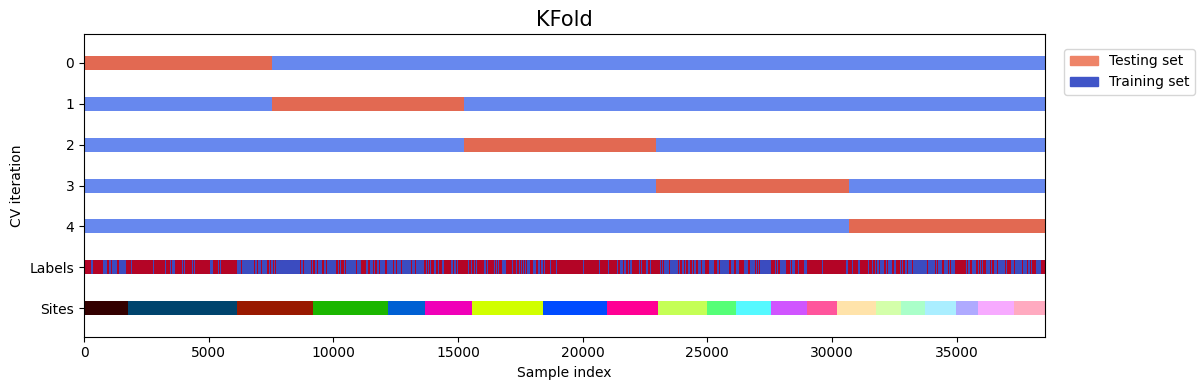

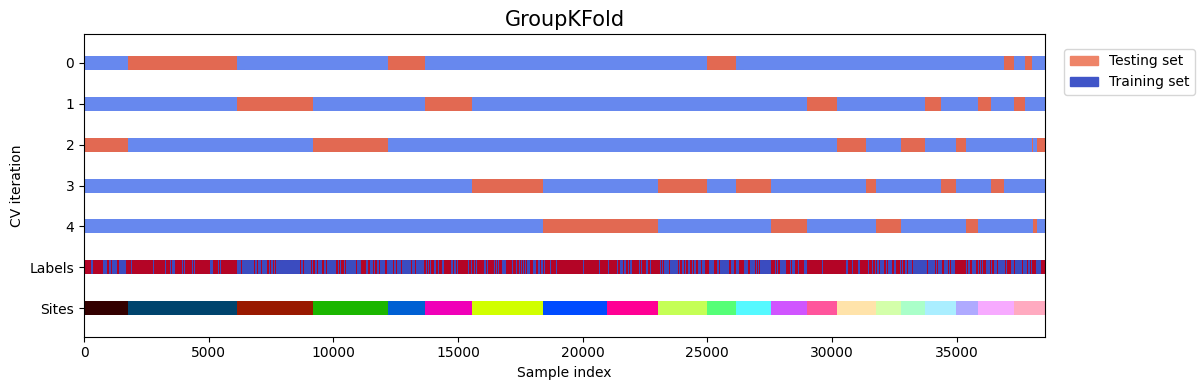

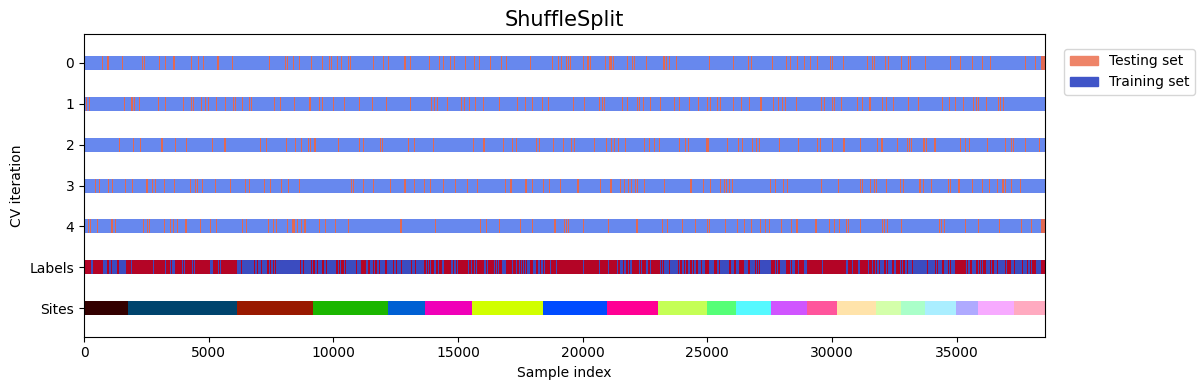

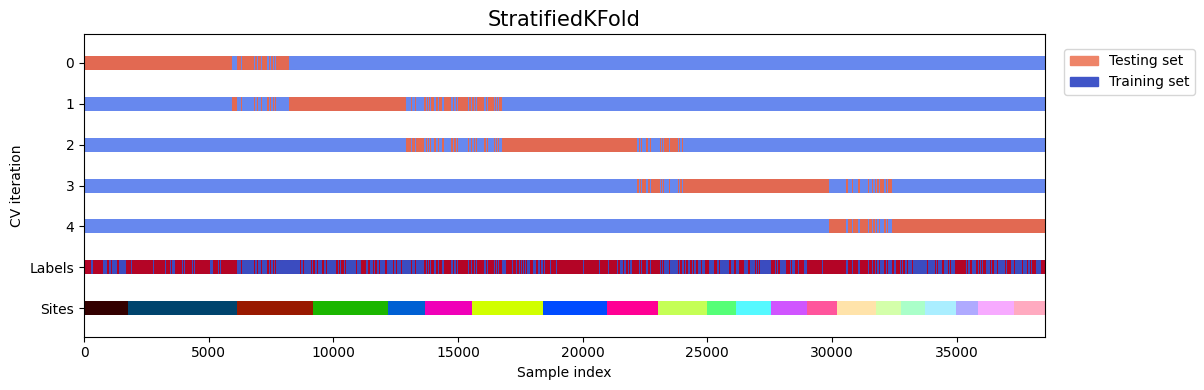

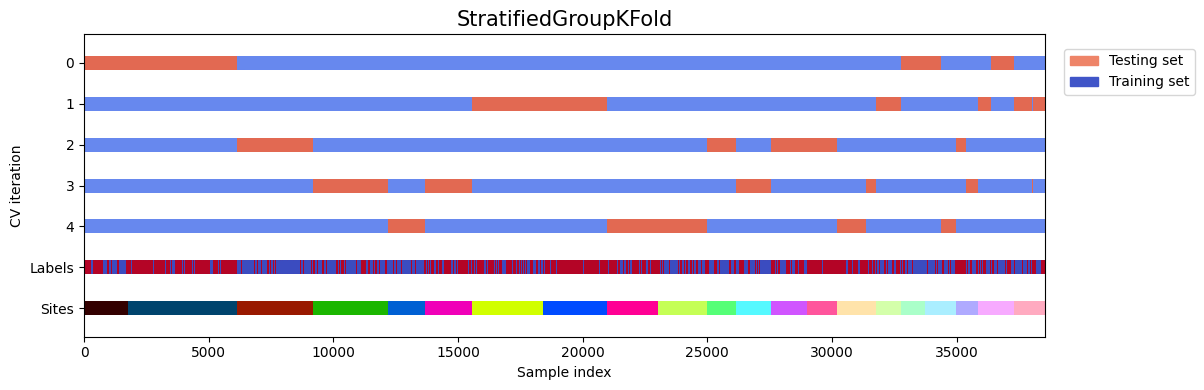

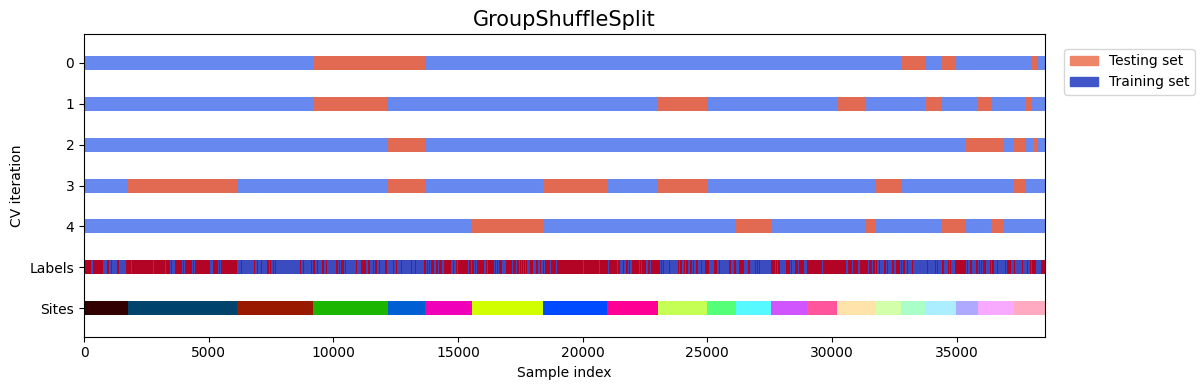

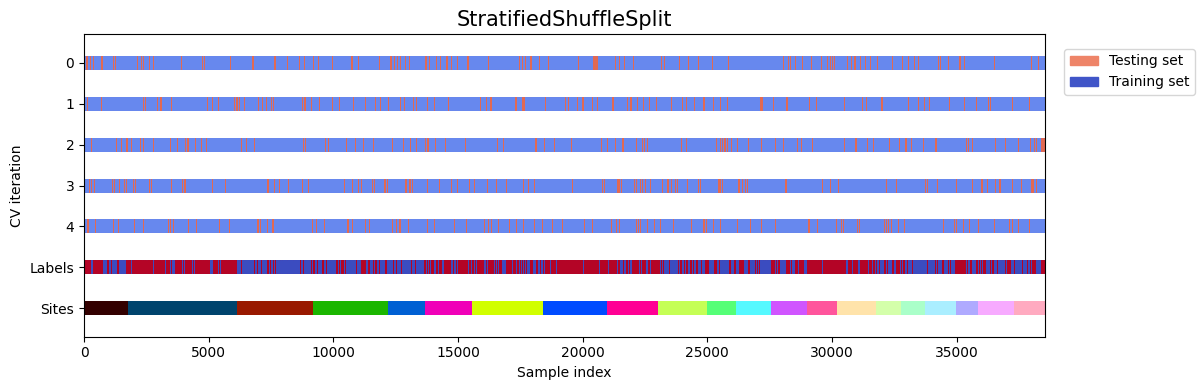

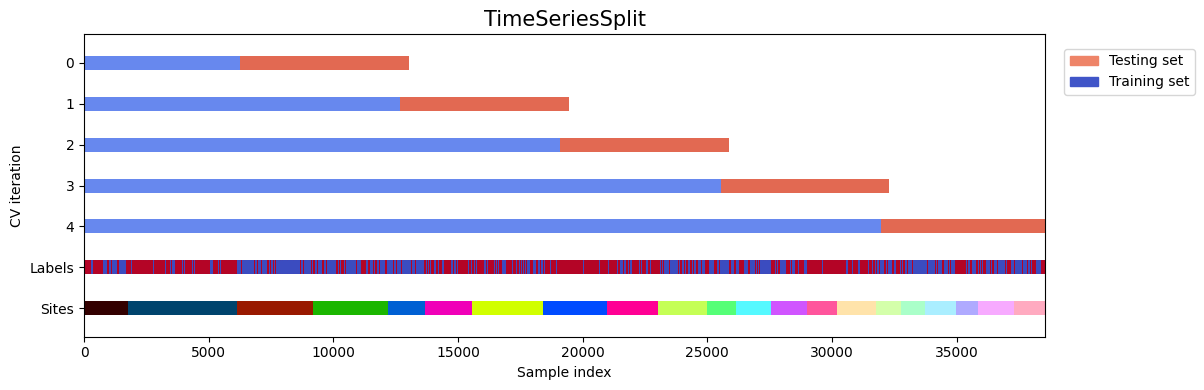

In [87]:
cvs = [
    KFold,
    GroupKFold,
    ShuffleSplit,
    StratifiedKFold,
    StratifiedGroupKFold,
    GroupShuffleSplit,
    StratifiedShuffleSplit,
    TimeSeriesSplit,
]


for cv in cvs:
    this_cv = cv(n_splits=n_splits)
    fig, ax = plt.subplots(figsize=(15, 4))
    plot_cv_indices(this_cv, fpr, y, group_indices, ax, n_splits)

    ax.legend(
        [Patch(color=cmap_cv(0.8)), Patch(color=cmap_cv(0.02))],
        ["Testing set", "Training set"],
        loc=(1.02, 0.8),
    )
    # Make the legend fit
    plt.tight_layout()
    fig.subplots_adjust(right=0.7)
plt.show()

There is a distinct difference between methods with grouping and they shall be used for all site dataset.